# Módulo 8: ¿quién será All-Star o All-NBA? (y el MVP)

**Preguntas:**
- **H.** ¿Cuántos All-Stars acierta un ranking simple por puntos por partido a mitad de temporada, y cuánto mejora un modelo?
- **I.** ¿Está el MVP real entre los 3 mejores por PIE?
- ¿Aporta algo la **reputación** (haber sido All-Star antes) más allá de las estadísticas?

**Diseño (decidido antes de ver los datos):**
- **Sin fuga de información:** el All-Star se vota a mitad de temporada, así que el panel de All-Star usa estadísticas hasta la fecha en que se jugó la mitad del calendario; el panel de All-NBA (se anuncia al final) usa la temporada completa.
- **Validación temporal:** ventana creciente. Para predecir la temporada T se entrena solo con temporadas anteriores; primera temporada de prueba, 2019-20 (7 temporadas de prueba).
- **Candidatos:** los 80 con más puntos por partido en el corte (con mínimo de partidos).
- **Baselines primero:** ranking por puntos por partido y por PIE; después regresión logística (solo puntos, con estadísticas, con estadísticas + reputación) y XGBoost.
- **Métrica principal:** precisión@R: de los R ganadores reales de la temporada, cuántos están entre los R primeros del modelo. Además log loss, Brier y mejora pareada con intervalo.
- MVP: NBA.com da solo el ganador (11 en 11 temporadas), así que **no se entrena**: se mira el puesto que ocupa el MVP real en distintos rankings.

**Mis hipótesis previas:** ninguna ("sin intuición, corre"). Referencias: el ranking por puntos.

Para reproducir: `scripts/download_awards.py` y `scripts/awards_experiment.py` (guardan resultados en `data/processed/`), luego `python -m uv run jupyter lab`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from sportslab.config import PROCESSED_DIR
from sportslab.data import NbaClient
from sportslab.data.awards import award_labels, load_awards_for
from sportslab.data.games import load_games, season_labels
from sportslab.data.player_season import cutoff_at_fraction, load_player_season
from sportslab.features.awards import ALL_STAR_FEATURES, as_matrix, build_panel
from sportslab.models.awards_model import make_logistic
from sportslab.models.metrics import calibration_table

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 200

pred = pd.read_parquet(PROCESSED_DIR / "awards_predictions.parquet")
per_season = pd.read_parquet(PROCESSED_DIR / "awards_per_season.parquet")
pooled = pd.read_parquet(PROCESSED_DIR / "awards_pooled.parquet")
mvp = pd.read_parquet(PROCESSED_DIR / "awards_mvp.parquet")
print(
    f"{len(pred)} predicciones fuera de muestra; temporadas de prueba: {sorted(pred['test_season'].unique())}"
)

1120 predicciones fuera de muestra; temporadas de prueba: ['2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25', '2025-26']


## 0. Tres hallazgos de datos

1. **Un solo endpoint da los premios** (`PlayerAwards`, una petición por jugador, historial completo): selecciones All-Star, All-NBA con número de equipo y MVP. De MVP solo viene el *ganador*, no los votos.
2. **Mi primer corte fijo (15 de enero) rompió 2020-21.** Esa temporada empezó el 22 de diciembre; al 15 de enero nadie llevaba 15 partidos y el panel salió **vacío** (0 candidatos). El script de cobertura lo mostró de inmediato. Lo cambié a "la fecha en que se jugó la mitad del calendario", que es comparable entre temporadas.
3. **Los candidatos (top 80 por puntos) dejan fuera a algún All-Star real** (p. ej. 2017-18: 26 de 28 en el panel). Es una limitación del diseño que se ve en la tabla de cobertura del script, no un error escondido.

## 1. All-Star (estadísticas a mitad de temporada)

 season  winners  score_rank_pts  score_rank_pie  p_pts_only  p_stats  p_logit_all  p_xgb_all
2019-20       25           0.640           0.640       0.640    0.760        0.720      0.760
2020-21       26           0.769           0.731       0.769    0.808        0.846      0.808
2021-22       25           0.680           0.720       0.680    0.760        0.760      0.800
2022-23       27           0.815           0.741       0.815    0.852        0.852      0.778
2023-24       26           0.769           0.692       0.769    0.923        0.923      0.923
2024-25       26           0.654           0.692       0.654    0.846        0.846      0.846
2025-26       28           0.750           0.714       0.750    0.857        0.857      0.786

Promedio precisión@R: {'score_rank_pts': 0.725, 'score_rank_pie': 0.704, 'p_pts_only': 0.725, 'p_stats': 0.829, 'p_logit_all': 0.829, 'p_xgb_all': 0.814}
Equivalente en All-Stars (de ~26): {'score_rank_pts': 18.9, 'score_rank_pie': 18.3, 'p_pts_on

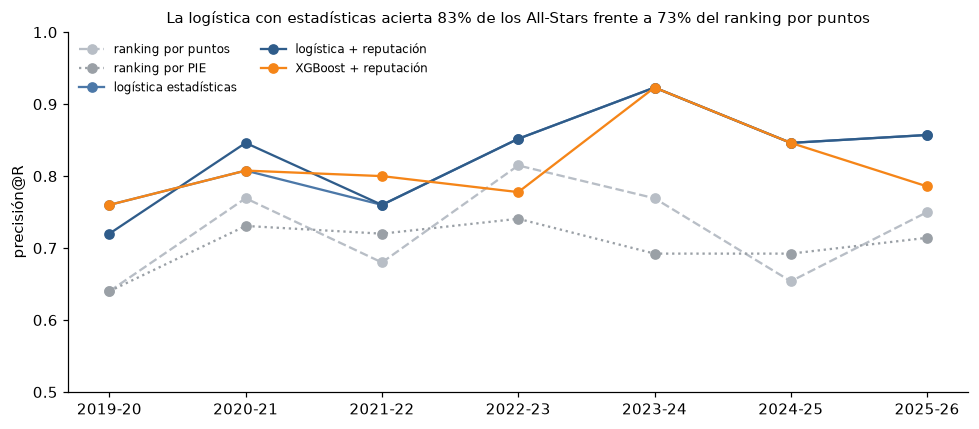

In [2]:
ps = per_season[per_season["panel"] == "all_star"].drop(columns="panel")
labels = {
    "score_rank_pts": "ranking por puntos",
    "score_rank_pie": "ranking por PIE",
    "p_pts_only": "logística solo puntos",
    "p_stats": "logística estadísticas",
    "p_logit_all": "logística + reputación",
    "p_xgb_all": "XGBoost + reputación",
}
print(ps.to_string(index=False))
means = ps[list(labels)].mean()
print("\nPromedio precisión@R:", means.round(3).to_dict())
print("Equivalente en All-Stars (de ~26):", (means * 26).round(1).to_dict())

fig, ax = plt.subplots(figsize=(9, 4))
for col, color, ls in (
    ("score_rank_pts", "#B8BEC6", "--"),
    ("score_rank_pie", "#9AA0A6", ":"),
    ("p_stats", "#4C78A8", "-"),
    ("p_logit_all", "#2F5C8A", "-"),
    ("p_xgb_all", "#F58518", "-"),
):
    ax.plot(ps["season"], ps[col], marker="o", color=color, ls=ls, label=labels[col])
ax.set_ylim(0.5, 1)
ax.set_ylabel("precisión@R")
ax.set_title(
    f"La logística con estadísticas acierta {means['p_stats']:.0%} de los All-Stars frente a "
    f"{means['score_rank_pts']:.0%} del ranking por puntos",
    fontsize=10,
)
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [3]:
better = (ps["p_stats"] > ps["score_rank_pts"]).sum()
print(
    f"La logística con estadísticas supera al ranking por puntos en {better} de {len(ps)} temporadas"
)
diff = ps["p_stats"] - ps["score_rank_pts"]
print(
    f"Diferencia media {diff.mean():+.3f} (mín {diff.min():+.3f}, máx {diff.max():+.3f}); "
    f"con reputación vs sin: {(ps['p_logit_all'] - ps['p_stats']).mean():+.3f}"
)
print()
print(pooled[pooled["panel"] == "all_star"].drop(columns="panel").set_index("model").to_string())

La logística con estadísticas supera al ranking por puntos en 7 de 7 temporadas
Diferencia media +0.104 (mín +0.037, máx +0.192); con reputación vs sin: -0.000

           log_loss  brier  gain_vs_reference  gain_low  gain_high
model                                                             
pts_only      0.452  0.143                NaN       NaN        NaN
stats         0.263  0.081              0.188     0.148      0.228
logit_all     0.267  0.082              0.185     0.143      0.226
xgb_all       0.275  0.086              0.177     0.138      0.216


**Lectura de H.** Un ranking por puntos a mitad de temporada acierta ~72 % de los All-Stars (unos 19 de 26). Una logística con estadísticas básicas sube a ~83 % (unos 22 de 26) y supera al ranking por puntos en las 7 temporadas de prueba; la mejora en log loss (0.45 → 0.26) tiene un intervalo lejos de 0. **La reputación (haber sido All-Star antes) no añade nada**: logística con y sin reputación quedan prácticamente iguales, y **XGBoost no supera a la logística**. Misma lección que en el Módulo 1: pocos datos y señal casi lineal, el modelo simple basta.

**Cuidado con los intervalos:** las 560 filas (7 temporadas × 80 candidatos) no son independientes (los mismos jugadores se repiten año tras año), así que el intervalo de la mejora está algo optimista.

In [4]:
last = (
    pred[(pred["panel"] == "all_star") & (pred["test_season"] == "2025-26")]
    .sort_values("p_stats", ascending=False)
    .reset_index(drop=True)
)
r = int(last["all_star"].sum())
print(
    f"2025-26: {r} All-Stars en el panel. Los {r} primeros del modelo contienen {int(last.head(r)['all_star'].sum())}."
)
print("\nAll-Stars reales que el modelo dejó fuera de sus primeros R:")
for i, row in last.iloc[r:][last.iloc[r:]["all_star"]].iterrows():
    print(
        f"  {row['player']:<26s} puesto {i + 1:>2d}  p={row['p_stats']:.2f}  pts={row['pts']:.1f}  equipo ganó {row['team_w_pct']:.0%}"
    )
print("\nEntre los primeros del modelo pero que no fueron All-Stars:")
for i, row in last.head(r)[~last.head(r)["all_star"]].iterrows():
    print(
        f"  {row['player']:<26s} puesto {i + 1:>2d}  p={row['p_stats']:.2f}  pts={row['pts']:.1f}  equipo ganó {row['team_w_pct']:.0%}"
    )

2025-26: 28 All-Stars en el panel. Los 28 primeros del modelo contienen 24.

All-Stars reales que el modelo dejó fuera de sus primeros R:
  LeBron James               puesto 30  p=0.24  pts=22.7  equipo ganó 62%
  De'Aaron Fox               puesto 34  p=0.16  pts=20.4  equipo ganó 68%
  Pascal Siakam              puesto 42  p=0.08  pts=23.6  equipo ganó 24%
  Norman Powell              puesto 45  p=0.07  pts=23.9  equipo ganó 51%

Entre los primeros del modelo pero que no fueron All-Stars:
  James Harden               puesto 12  p=0.92  pts=25.8  equipo ganó 56%
  Julius Randle              puesto 15  p=0.87  pts=22.6  equipo ganó 64%
  Austin Reaves              puesto 25  p=0.54  pts=26.6  equipo ganó 62%
  Amen Thompson              puesto 28  p=0.34  pts=18.5  equipo ganó 62%


Los errores del modelo son los casos que un modelo de estadísticas no puede ver: votos de aficionados, cupos por conferencia y reemplazos por lesión. No se trata de afinar más; la información no está en los datos.

## 2. Calibración y qué pesa

¿Las probabilidades dicen la verdad? Y, mirando en la muestra completa solo para interpretar (no para evaluar), qué características importan.

 bin   n  mean_pred  observed  ci_low  ci_high
   0 257      0.023     0.027   0.013    0.055
   1  50      0.148     0.120   0.056    0.238
   2  28      0.249     0.214   0.102    0.395
   3  26      0.351     0.231   0.110    0.421
   4  17      0.446     0.412   0.216    0.640
   5  18      0.557     0.389   0.203    0.614
   6  20      0.651     0.600   0.387    0.781
   7  16      0.754     0.875   0.640    0.965
   8  34      0.858     0.824   0.665    0.917
   9  94      0.969     0.957   0.896    0.983


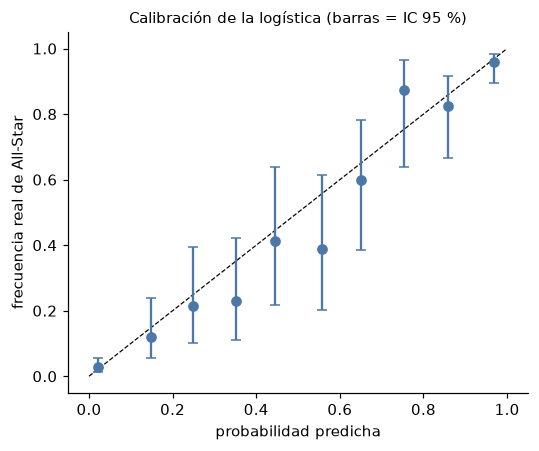

In [5]:
g = pred[pred["panel"] == "all_star"]
cal = calibration_table(g["all_star"].astype(float).to_numpy(), g["p_stats"].to_numpy(), n_bins=10)
print(cal.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 4.2))
ax.plot([0, 1], [0, 1], color="k", lw=0.8, ls="--")
ax.errorbar(
    cal["mean_pred"],
    cal["observed"],
    yerr=[cal["observed"] - cal["ci_low"], cal["ci_high"] - cal["observed"]],
    fmt="o",
    color="#4C78A8",
    capsize=3,
)
ax.set_xlabel("probabilidad predicha")
ax.set_ylabel("frecuencia real de All-Star")
ax.set_title("Calibración de la logística (barras = IC 95 %)", fontsize=10)
plt.tight_layout()
plt.show()

Las probabilidades están razonablemente calibradas: el 97 % predicho se da ~96 % de las veces y el 2 % predicho, ~3 %; los tramos del medio tienen pocos casos (16-28) y sus intervalos incluyen la diagonal.

Coeficientes estandarizados de la logística (muestra completa, solo para interpretar):
ast               0.090
ts_pct            0.140
reb               0.290
prior_all_stars   0.300
pts               0.470
min_pg            0.680
usg_pct           1.040
gp_frac           1.130
pie               1.310
team_w_pct        1.520


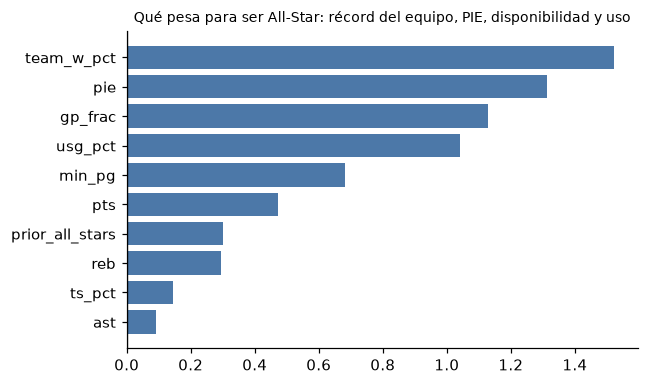

In [6]:
client = NbaClient()
SEASONS = season_labels(2015, 2025)
games = load_games(client, SEASONS)
stats = pd.concat(
    [load_player_season(client, s, cutoff_at_fraction(games, s)) for s in SEASONS],
    ignore_index=True,
)
ids = sorted(
    {
        pid
        for s in SEASONS
        for pid in stats[(stats["season"] == s) & (stats["gp"] >= 15)].nlargest(80, "pts")[
            "player_id"
        ]
    }
)
awards = load_awards_for(client, ids)
labels_df = award_labels(awards)
panel = pd.concat(
    [build_panel(stats, awards, labels_df, s, 80, 15) for s in SEASONS], ignore_index=True
)
model = make_logistic().fit(as_matrix(panel, ALL_STAR_FEATURES), panel["all_star"].astype(int))
coef = pd.Series(model[-1].coef_[0], index=ALL_STAR_FEATURES).sort_values()
print("Coeficientes estandarizados de la logística (muestra completa, solo para interpretar):")
print(coef.round(2).to_string())
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.barh(coef.index, coef.values, color=["#E45756" if v < 0 else "#4C78A8" for v in coef.values])
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Qué pesa para ser All-Star: récord del equipo, PIE, disponibilidad y uso", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura.** Lo que más pesa es el **récord del equipo** (1.5), el **PIE** (1.3), la **disponibilidad** (partidos jugados sobre el máximo, 1.1) y el **uso** (1.0); los puntos por partido pesan bastante menos (0.5) porque se solapan con uso, minutos y PIE. La reputación tiene un peso positivo pero pequeño (0.3). Con variables tan correlacionadas entre sí los coeficientes individuales no son estables: sirve para ver el orden de magnitud, no para decir que "el equipo importa el triple que los puntos". Sí es llamativo que jugar para un equipo ganador y estar sano pese tanto: el All-Star premia más que el rendimiento individual.

## 3. All-NBA (temporada completa)

In [7]:
pn = per_season[per_season["panel"] == "all_nba"].drop(columns="panel")
print(pn.to_string(index=False))
means_n = pn[list(labels)].mean()
print("\nPromedio precisión@R:", means_n.round(3).to_dict())
print(pooled[pooled["panel"] == "all_nba"].drop(columns="panel").set_index("model").to_string())

 season  winners  score_rank_pts  score_rank_pie  p_pts_only  p_stats  p_logit_all  p_xgb_all
2019-20       15           0.533           0.600       0.533    0.733        0.733      0.800
2020-21       14           0.571           0.571       0.571    0.714        0.714      0.714
2021-22       14           0.929           0.571       0.929    0.929        0.857      0.857
2022-23       15           0.667           0.733       0.667    0.800        0.800      0.733
2023-24       15           0.733           0.733       0.733    0.867        0.933      0.867
2024-25       15           0.467           0.400       0.467    0.867        0.867      0.800
2025-26       15           0.600           0.667       0.600    0.933        0.933      0.800

Promedio precisión@R: {'score_rank_pts': 0.643, 'score_rank_pie': 0.611, 'p_pts_only': 0.643, 'p_stats': 0.835, 'p_logit_all': 0.834, 'p_xgb_all': 0.796}
           log_loss  brier  gain_vs_reference  gain_low  gain_high
model                     

**Lectura.** All-NBA es una pregunta más "limpia" (sin votos de aficionados): el ranking por puntos acierta ~64 % (unos 10 de 15) y la logística ~83 % (unos 12.5 de 15), con mejora de log loss de 0.33 a 0.15. Otra vez la reputación no suma y XGBoost queda por debajo.

## 4. Hipótesis I: el MVP

In [8]:
print(mvp.set_index("season").round(0).astype("Int64").to_string(na_rep="-"))
n = int(mvp["end_rank_pie"].notna().sum())
print(
    f"\nMVP entre los 3 primeros por PIE a mitad de temporada: {int((mvp['mid_rank_pie'] <= 3).sum())} de {n}"
)
print(f"MVP entre los 3 primeros por PIE al final: {int((mvp['end_rank_pie'] <= 3).sum())} de {n}")
tail = mvp.dropna(subset=["end_rank_model"])
print(
    f"\nEn las {len(tail)} temporadas de prueba: MVP 1.º por el modelo All-NBA en {int((tail['end_rank_model'] == 1).sum())}, "
    f"1.º por PIE en {int((tail['end_rank_pie'] == 1).sum())}, 1.º por puntos en {int((tail['end_rank_pts'] == 1).sum())}, "
    f"1.º por % de victorias del equipo en {int((tail['end_rank_team_w_pct'] == 1).sum())}"
)

         mid_rank_pie  mid_rank_pts  mid_rank_team_w_pct  end_rank_pie  end_rank_pts  end_rank_team_w_pct  end_rank_model
season                                                                                                                   
2015-16             1             1                    3             1             1                    3            <NA>
2016-17             1             1                   34             1             1                   30            <NA>
2017-18             4             1                   13             1             1                    4            <NA>
2018-19             1             9                    5             1             3                    5            <NA>
2019-20             1             2                    3             1             5                    2               1
2020-21             2            10                   24             2            13                   16               1
2021-22             1   

**Lectura de I.** El MVP real estuvo entre los 3 primeros por PIE en 9 de 11 temporadas a mitad de campaña y en 10 de 11 al final: es casi siempre un jugador estadísticamente de élite, pero el primero por PIE lo es solo en 7 de 11 años. Al ordenar por la probabilidad de All-NBA del modelo (entrenado solo con All-NBA, sin ver ningún MVP), el MVP real queda **primero en las 7 temporadas de prueba**; por PIE solo en 3 de las 7, por puntos en 2 y por récord del equipo en ninguna.

**Cuidado:** 7 temporadas son 7 casos. Que el MVP sea el primero del modelo dice que el modelo describe bien "quién tuvo la mejor temporada en estadísticas, equipo y trayectoria"; no dice que prediga el voto de los periodistas, que incluye narrativa. Y con las probabilidades de los 3-4 primeros todas por encima de 0.97, el orden entre ellos depende de diferencias diminutas del puntaje lineal.

## 5. Resultado vs. hipótesis

No hubo hipótesis previa. Contra el ranking por puntos:

| Pregunta | Resultado (7 temporadas de prueba) | Veredicto |
|---|---|---|
| H. All-Star con puntos por partido | ~72 % (≈19 de 26) | Un buen baseline |
| H. Modelo logístico con estadísticas | ~83 % (≈22 de 26); mejor en 7 de 7 temporadas | Mejora clara |
| ¿Reputación? | Sin cambio con reputación | No aporta |
| ¿XGBoost? | ~81 %, no supera a la logística | No aporta |
| All-NBA | 64 % baseline → 83 % logística | Mejora clara |
| I. MVP en el top 3 por PIE | 9 de 11 (mitad), 10 de 11 (final) | Casi siempre |
| MVP primero según el modelo All-NBA | 7 de 7 | Llamativo, pero son 7 casos |

**Qué mejorar (no hecho):** votos reales de aficionados (necesitarían un CSV tuyo); cupos por conferencia (12 y 12 más el reemplazo por lesión); una predicción con probabilidades de MVP a partir de porcentajes de voto (también CSV); candidatos más amplios que los 80 primeros por puntos; validar en más temporadas (solo hay 7 de prueba).

## 6. Tus ejercicios

1. **Predice y mide.** Cambia el corte de mitad de temporada a 30 % del calendario. Antes de correr, predice si la precisión@R del All-Star sube o baja, y si la reputación empezará a aportar. Luego mídelo.
2. **Mira un error.** Elige un All-Star real que el modelo dejó fuera (por ejemplo del listado de 2025-26) y busca qué lo explica (¿lesión?, ¿equipo de su conferencia?, ¿votos de aficionados?). Qué información necesitaría un modelo para acertarlo.